In [ ]:
In a reactor the reaction  A + B = C reaches equilibrium. Initial concentration are A=1.5 ,B=1.0 AND C=0 mol/L of C is formed , kc=x/((1.5-x)(1-x)), which rearrange the quadratic equaction Kc.x2-(2.5Kc+1).X + 1.5kC =0  i want to write python programe 
read Kc using input (), prints the data type of the raw input and of the converted value , and shoe a clear message (no crash) if the text is not a number or if kc less than or equal to 0 ; give code on this i will mentioned my promt above i will give you Kc=4, Kc=0.5, Kc=abc and Kc=-2
                    

In [1]:
import math

A0 = 1.5
B0 = 1.0

raw_kc = input("Enter Kc: ")
print(f"Raw input: {raw_kc!r}")
print(f"Raw input type: {type(raw_kc).__name__}")

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: please enter Kc as a number, such as 4 or 0.5.")
else:
    print(f"Converted value: {kc}")
    print(f"Converted value type: {type(kc).__name__}")

    if not math.isfinite(kc):
        print("Invalid Kc: please enter a finite number.")
    elif kc <= 0:
        print("Invalid Kc: Kc must be greater than 0.")
    else:
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc

        print(f"a = {a}")
        print(f"b = {b}")
        print(f"c = {c}")

        discriminant = b**2 - 4 * a * c
        print(f"Discriminant: {discriminant:.4f}")

        root1 = (-b + math.sqrt(discriminant)) / (2 * a)
        root2 = (-b - math.sqrt(discriminant)) / (2 * a)
        print(f"Root 1: {root1:.4f}")
        print(f"Root 2: {root2:.4f}")

        physical_roots = [root for root in (root1, root2) if 0 <= root <= B0]

        if physical_roots:
            x = physical_roots[0]
            A = A0 - x
            B = B0 - x
            C = x
            print(f"Equilibrium extent x: {x:.4f} mol/L")
            print("Equilibrium concentrations:")
            print(f"A = {A:.4f} mol/L")
            print(f"B = {B:.4f} mol/L")
            print(f"C = {C:.4f} mol/L")
        else:
            print("No root satisfies the physical constraint 0 <= x <= 1.0.")

Raw input: '4'
Raw input type: str
Converted value: 4.0
Converted value type: float
Discriminant: 25.0000
Root 1: 2.0000
Root 2: 0.7500
Equilibrium extent x: 0.7500 mol/L
Equilibrium concentrations:
A = 0.7500 mol/L
B = 0.2500 mol/L
C = 0.7500 mol/L


find a,b,c, the discriminant and both roots 

In [2]:
a = kc
b = -(2.5 * kc + 1)
c = 1.5 * kc

print(f"a = {a}")
print(f"b = {b}")
print(f"c = {c}")

discriminant = b**2 - 4 * a * c
print(f"Discriminant: {discriminant:.4f}")

root1 = (-b + math.sqrt(discriminant)) / (2 * a)
root2 = (-b - math.sqrt(discriminant)) / (2 * a)

print(f"Root 1: {root1:.4f}")
print(f"Root 2: {root2:.4f}")

a = 4.0
b = -11.0
c = 6.0
Discriminant: 25.0000
Root 1: 2.0000
Root 2: 0.7500


Select the physically meaningful root. Since B starts at 1.0 mol/L and is the limiting reactant, the extent must satisfy `0 < x < 1.0` for finite positive Kc so that both reactant concentrations remain positive.

In [5]:
# Select the root that keeps both reactant concentrations positive.
physical_roots = [root for root in (root1, root2) if 0 < root < B0]

if physical_roots:
    x = physical_roots[0]
    print(f"Physically meaningful root: x = {x:.4f} mol/L")
    print(f"At this root, [A] = {A0 - x:.4f} mol/L")
    print(f"At this root, [B] = {B0 - x:.4f} mol/L")
else:
    print("Neither root is physically meaningful because 0 < x < 1.0 is not satisfied.")

Physically meaningful root: x = 0.7500 mol/L
At this root, [A] = 0.7500 mol/L
At this root, [B] = 0.2500 mol/L


Print the equilibrium concentrations [A]eq, [B]eq and [C]eq to 3 decimal places. Calculate the conversion of limiting reactant B as (x / [B]initial) × 100%.

In [6]:
A_eq = A0 - x
B_eq = B0 - x
C_eq = x

conversion_B = (x / B0) * 100

print("Equilibrium concentrations:")
print(f"[A]eq = {A_eq:.3f} mol/L")
print(f"[B]eq = {B_eq:.3f} mol/L")
print(f"[C]eq = {C_eq:.3f} mol/L")
print(f"Conversion of limiting reactant B = {conversion_B:.3f}%")

Equilibrium concentrations:
[A]eq = 0.750 mol/L
[B]eq = 0.250 mol/L
[C]eq = 0.750 mol/L
Conversion of limiting reactant B = 75.000%


classifies the conversion using if/ elif /else:> than equal to 70% "High",>than equal to 40% "moderate", otherwisw "low" 

In [7]:
if conversion_B >= 70:
    conversion_level = "High"
elif conversion_B >= 40:
    conversion_level = "Moderate"
else:
    conversion_level = "Low"

print(f"Conversion category: {conversion_level}")

Conversion category: High


part A in a batch reactor , reactant a is consumed by first-order reactin , dC/dt=-kc. use the eulars method; c_old -k.c_old.change in t initial C =2.5 mol/lit, k=0.04min inverse change in time is 1 min. 


1) using for loop simulate 12 minutes and print a table of time (minute)  , concentration (mol/lit) and conversion(%)

In [8]:
# Euler simulation for a first-order batch reaction: dC/dt = -kC
C0 = 2.5       # Initial concentration (mol/L)
k = 0.04       # Rate constant (1/min)
dt = 1          # Time step (min)
total_time = 12 # Total simulation time (min)

concentration = C0
conversion = 0.0

print("Time (min) | Concentration (mol/L) | Conversion (%)")
print(f"{0:10d} | {concentration:22.3f} | {conversion:14.2f}")

for time in range(1, total_time + 1):
    concentration = concentration - k * concentration * dt
    conversion = (C0 - concentration) / C0 * 100
    print(f"{time:10d} | {concentration:22.3f} | {conversion:14.2f}")

Time (min) | Concentration (mol/L) | Conversion (%)
         0 |                  2.500 |           0.00
         1 |                  2.400 |           4.00
         2 |                  2.304 |           7.84
         3 |                  2.212 |          11.53
         4 |                  2.123 |          15.07
         5 |                  2.038 |          18.46
         6 |                  1.957 |          21.72
         7 |                  1.879 |          24.86
         8 |                  1.803 |          27.86
         9 |                  1.731 |          30.75
        10 |                  1.662 |          33.52
        11 |                  1.596 |          36.18
        12 |                  1.532 |          38.73


using math.exp(), calculate the exact value c inital e to the power (-kt) at 12 min and print the absolute error of the eulars result.

In [11]:
import math

exact_concentration = C0 * math.exp(-k * total_time)
euler_concentration = concentration
absolute_error = abs(exact_concentration - euler_concentration)

print(f"Exact concentration at {total_time} min: {exact_concentration:.6f} mol/L")
print(f"Euler concentration at {total_time} min: {euler_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

Exact concentration at 12 min: 1.546958 mol/L
Euler concentration at 12 min: 1.470503 mol/L
Absolute error: 0.076455 mol/L


using while loop, repeat the simulation until conversion reaches 40% or time reaches 100 min. print the time needed and the final concentration.

In [10]:
# Euler simulation until conversion reaches 40% or time reaches 100 min.
C0 = 2.5
k = 0.04
dt = 1

time = 0
concentration = C0
conversion = 0.0

while conversion < 40 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (C0 - concentration) / C0 * 100

if conversion >= 40:
    print("The 40% conversion target was reached.")
else:
    print("The 100-minute time limit was reached.")

print(f"Time needed: {time:.0f} min")
print(f"Final concentration: {concentration:.3f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

The 40% conversion target was reached.
Time needed: 13 min
Final concentration: 1.471 mol/L
Final conversion: 41.18%


part b distillation _coloumn sample codes such as DIST2026X9Q3 are stored as text. write a program that read code , loop through each character, and print the number of digits and the sum of the digits. show a message for an wmpty code and for code with no digits. test with DIST2026X9Q3 , an empty code and ABCDEF

In [14]:
# Test the digit counter with the requested batch-code examples.
sample_codes = ["DIST2026X9Q3", "", "ABCDEF"]

for code in sample_codes:
    print(f"\nBatch code: {code!r}")

    if code == "":
        print("The batch code is empty.")
        continue

    digit_count = 0
    digit_sum = 0

    for character in code:
        if character.isdigit():
            digit = int(character)
            digit_count += 1
            digit_sum += digit

    if digit_count == 0:
        print("The batch code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


Batch code: 'DIST2026X9Q3'
Number of digits: 6
Sum of digits: 22

Batch code: ''
The batch code is empty.

Batch code: 'ABCDEF'
The batch code contains no digits.


part a a laboratory has n candidate solvent and wants to test r of them together in a mixed solvent(order does not matter). write a recursive function factorial (n)(remember the base case for 0 facrorial)and function combination(n,r)= n factorial/(r factorial(n-r)factorial)that uses it reject invalid input (negetive values,r greater than n). print the number of possible mixtures for n=9, r=3 and show the message for n=6, r= 8

In [1]:
def factorial(number):
    if number < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if number == 0 or number == 1:
        return 1
    return number * factorial(number - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must be nonnegative integers.")
    if r > n:
        raise ValueError("r cannot be greater than n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


try:
    print(f"Number of mixtures for n=9, r=3: {combination(9, 3)}")
except ValueError as error:
    print(f"Invalid input: {error}")

try:
    print(f"Number of mixtures for n=6, r=8: {combination(6, 8)}")
except ValueError as error:
    print(f"Invalid input for n=6, r=8: {error}")

Number of mixtures for n=9, r=3: 84
Invalid input for n=6, r=8: r cannot be greater than n.


part b during  a crystallisation run, sample are taken at time =fibonacci number into 4 min writw an iterative function fib_iter(n) that returns a list of the first n fibonacci numbers , and a recursive function fib_rec(k) that returns the k th fibonacci number (f initial , f one =1 ) for n=10 check that both function are agree and print a table sample no. |fibonacci tag| sampling time (min)

In [2]:
def fib_iter(n):
    values = []
    previous, current = 0, 1

    for _ in range(n):
        values.append(previous)
        previous, current = current, previous + current

    return values


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be nonnegative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_values = fib_iter(n)
recursive_values = [fib_rec(index) for index in range(n)]

if fibonacci_values == recursive_values:
    print("Iterative and recursive Fibonacci values agree.")
else:
    print("The Fibonacci results do not agree.")

print("Sample no. | Fibonacci tag | Sampling time (min)")
for sample_number, fibonacci_tag in enumerate(fibonacci_values, start=1):
    sampling_time = fibonacci_tag * 4
    print(f"{sample_number:10d} | {fibonacci_tag:13d} | {sampling_time:19d}")

Iterative and recursive Fibonacci values agree.
Sample no. | Fibonacci tag | Sampling time (min)
         1 |             0 |                   0
         2 |             1 |                   4
         3 |             1 |                   4
         4 |             2 |                   8
         5 |             3 |                  12
         6 |             5 |                  20
         7 |             8 |                  32
         8 |            13 |                  52
         9 |            21 |                  84
        10 |            34 |                 136


consumption of reactant was studied in a batch reactor eith two feed concentration of catalyst the concentration(mol/l) was recorded 
time_min                run1_mol_l(low catalyst)            run2_mol_l(high catalyst) 
0                          1.50                                1.50
10                         1.17                                0.96 
20                         0.91                                0.61
30                         0.71                                0.39
40                         0.55                                0.25
50                         0.43                                0.16

a) create adata frame from this table. save it as akinetics.csv(without the index coloumn) and as kinetics.json read the csv back and print its shape and data types

In [1]:
import pandas as pd

data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_l_low_catalyst": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "run2_mol_l_high_catalyst": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
}

df = pd.DataFrame(data)

# Save to CSV without the index column, and save as JSON
df.to_csv("akinetics.csv", index=False)
df.to_json("kinetics.json", orient="records", indent=2)

# Read the CSV back and print its shape and data types
df_from_csv = pd.read_csv("akinetics.csv")
print("Shape:", df_from_csv.shape)
print("\nData types:")
print(df_from_csv.dtypes)

Shape: (6, 3)

Data types:
time_min                      int64
run1_mol_l_low_catalyst     float64
run2_mol_l_high_catalyst    float64
dtype: object


b) print the mean and std deviation of run1 run2 and state which run show more variation 

In [2]:
# df is the DataFrame created in part (a)
run1 = df["run1_mol_l_low_catalyst"]
run2 = df["run2_mol_l_high_catalyst"]

print(f"Run 1 mean: {run1.mean():.3f} mol/L")
print(f"Run 1 standard deviation: {run1.std():.3f} mol/L")

print(f"Run 2 mean: {run2.mean():.3f} mol/L")
print(f"Run 2 standard deviation: {run2.std():.3f} mol/L")

if run1.std() > run2.std():
    print("Run 1 shows more variation based on standard deviation.")
else:
    print("Run 2 shows more variation based on standard deviation.")

Run 1 mean: 0.878 mol/L
Run 1 standard deviation: 0.402 mol/L
Run 2 mean: 0.645 mol/L
Run 2 standard deviation: 0.507 mol/L
Run 2 shows more variation based on standard deviation.


c)plot both runs on one graph (time on x-axis) with title axis lable with units, legend and grid.

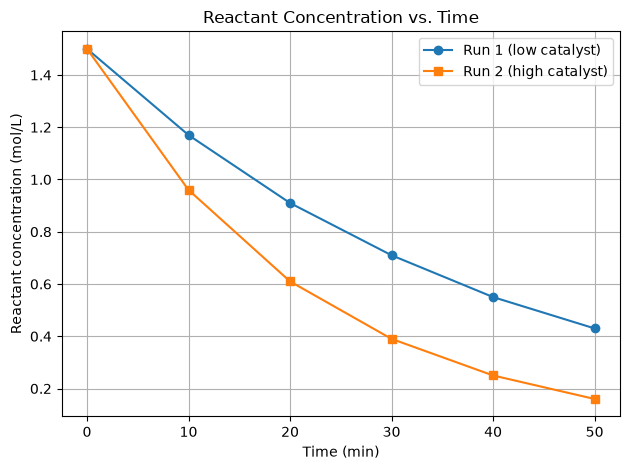

In [3]:
import matplotlib.pyplot as plt

# Uses the DataFrame `df` created in part (a)
plt.plot(df["time_min"], df["run1_mol_l_low_catalyst"], marker="o",
         label="Run 1 (low catalyst)")
plt.plot(df["time_min"], df["run2_mol_l_high_catalyst"], marker="s",
         label="Run 2 (high catalyst)")

plt.title("Reactant Concentration vs. Time")
plt.xlabel("Time (min)")
plt.ylabel("Reactant concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

d) ethylene gas is compressed slowly in apiston_cylinder at constant temprature:
volume_l 1 2 3 4 5
pressure_bar 5.03 2.52 1.65 1.26 1.01 respectively

plot pressure vs volume as ascatter plot. calculate k as the mean of pinto v and draw the reference curve p=k/v on the same graph add title labels with units and legend

k = 5.022 bar·L


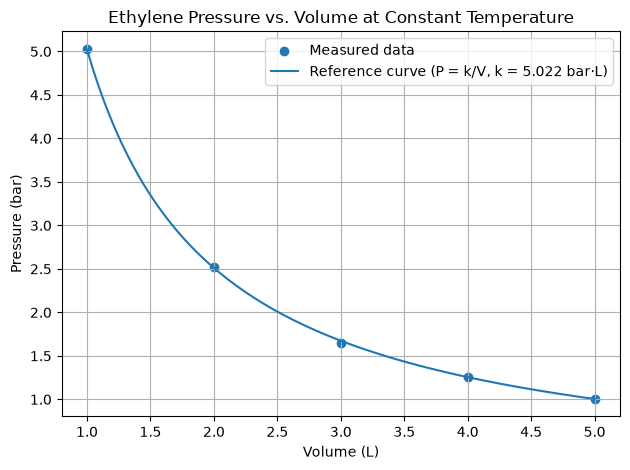

In [4]:
import numpy as np
import matplotlib.pyplot as plt

volume_l = np.array([1, 2, 3, 4, 5])
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01])

# Mean of P × V; units are bar·L
k = np.mean(pressure_bar * volume_l)
print(f"k = {k:.3f} bar·L")

# Smooth reference curve: P = k / V
volume_curve = np.linspace(volume_l.min(), volume_l.max(), 200)
pressure_curve = k / volume_curve

plt.scatter(volume_l, pressure_bar, label="Measured data")
plt.plot(volume_curve, pressure_curve, label=f"Reference curve (P = k/V, k = {k:.3f} bar·L)")

plt.title("Ethylene Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()